# Fleet Stable v1 — portable frozen Shadow Candidate
## tl;dr
Six real source machines (017/024/041/058/080/081), all eight modules considered. Unsupported data remain unsupported.
Local absolute levels/scales stay frozen; compatible donor correlation shapes assist them. This is a bounded robust empirical-moment approximation, not exact hierarchical posterior inference.
The bundle loads without notebook inputs or SQL. It does not certify healthy references, automatically activate, or vote in alerts.
## Context & Methods
### Key Assumptions
Naive source clock is treated as Asia/Bangkok. Pressure is owner-confirmed psi; psig/psia and configuration/state/controller/service contracts remain unverified. Same module index is a research stratum.
Reference and threshold periods are disjoint. Phase bounds use Fit-only Q90 of five contiguous minute coordinate ranges, floored at max(0.35 Local robust scale, 0.1 physical units). The previous 0.35-only phase rule could reject normal sensor movement. A stable phase is not a healthy label; response scores are never suppressed.
MX080/M6 proposed Fit is Aug27–30; threshold is Sep3–6. These intervals require engineering health review. The previously inspected Sep7–8 case is a regression, not prospective recall; the pre-case holdout is owner-proposed stable, not independently healthy.

In [1]:
from pathlib import Path
import json,sys
import numpy as np,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'apps/api').is_dir())
sys.path.insert(0,str(root))
from apps.api.app.fleet_bundle import load_package
from notebooks.support.fleet_stable_qa import day_rows
out=root/'notebooks/outputs/fleet_stable_v1_20261006'
build=json.loads((out/'build-summary.json').read_text(encoding='utf-8'))
qa=json.loads((out/'qa.json').read_text(encoding='utf-8'))
fleet=load_package(build['packages']['cp2_candidate'])
assert fleet.bundle_id==qa['bundle_id']
print('Frozen bundle:',fleet.bundle_id)
display(pd.DataFrame([qa['portable'],qa['parity']]))

Frozen bundle: fleet-stable-v1-2f656893533033ab994e3713


,zip_bytes,zip_sha256,exact_reload,requires_source_or_sql_for_inference,actual_points,max_absolute_error,max_relationship_error
0,131414.0,1566095c67d4b37777bdc07f58886ca032c478d31cf221...,True,False,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,43227.0,0.0,0.0


## Data
All source-day derivative SHA values reconcile to the frozen import/ZIP receipt corpus; this is not an exact current SQL snapshot. The original seconds and control events remain in their source stores. The package contains summary parameters, provenance and curation, not 46 million raw records.
Observed default-like temperatures -200 or all four module pressures 580.2 are acquisition review evidence. Audited Sep7 10:55:59–11:28:01 seconds quarantine outward-rounded 10:55–11:28 minute rows, including boundary mixtures. Future source adapters must report invalid-second membership; an average can hide a short bad burst.

status,FROZEN_SHADOW_CANDIDATE,INSUFFICIENT_THRESHOLD_CALIBRATION
machine,,
017,7,7
024,7,0
041,8,6
058,7,1
080,7,5
081,7,7


Verified days: 555 raw receipt rows: 46616484


,machine,module,context,n,fleet_weight,donor_machines
0,017,1,SV_OFF,2000,0.010391,"[024, 041, 058, 080, 081]"
1,017,2,SV_OFF,2025,0.010264,"[041, 058, 080, 081]"
2,017,3,SV_OFF,2037,0.010204,"[024, 041, 058, 081]"
3,017,4,SV_OFF,2026,0.010259,"[024, 058, 080, 081]"
4,017,5,SV_OFF,1938,0.010720,"[024, 058, 080, 081]"
5,017,6,SV_OFF,1971,0.010542,"[080, 081]"
6,017,8,SV_OFF,1924,0.007703,"[041, 058, 080, 081]"
7,024,1,SV_OFF,2214,0.009396,"[017, 041, 058, 080, 081]"
8,024,2,SV_OFF,2271,0.009162,"[058, 081]"
9,024,3,SV_OFF,2297,0.009060,"[017, 041, 058, 081]"


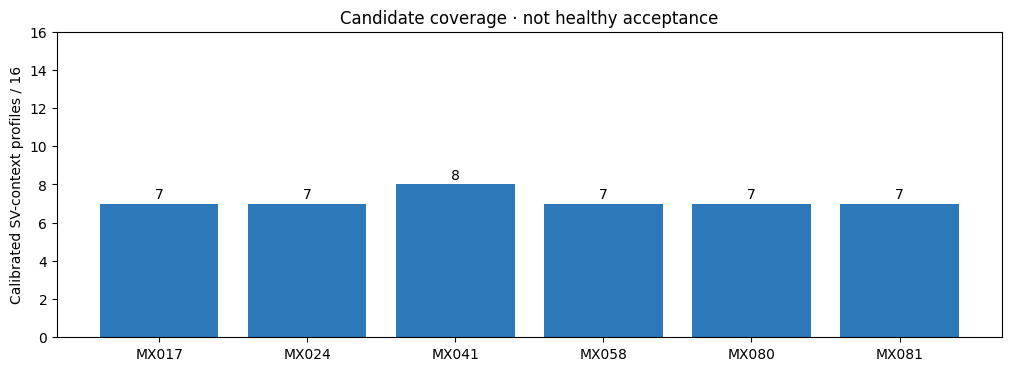

In [2]:
receipts=pd.DataFrame(build['calibration_receipts'])
display(receipts.groupby(['machine','status']).size().unstack(fill_value=0))
print('Verified days:',build['source_days_verified'],'raw receipt rows:',build['raw_rows'])
models=pd.DataFrame(fleet.models())
display(models[['machine','module','context','n','fleet_weight','donor_machines']])
fig,ax=plt.subplots(figsize=(10,3.6),layout='constrained')
counts=models.groupby('machine').size().reindex(['017','024','041','058','080','081'],fill_value=0)
ax.bar(['MX'+m for m in counts.index],counts.values,color='#2c78b8')
ax.set_ylim(0,16);ax.set_yticks(range(0,17,2));ax.set_ylabel('Calibrated SV-context profiles / 16')
ax.set_title('Candidate coverage · not healthy acceptance')
for i,n in enumerate(counts):ax.text(i,n+.25,str(n),ha='center')
fig.savefig(out/'profile-coverage.png',dpi=150);plt.show()

## Results
The case and acquisition incident have different meanings. Flat high CP2 remains outside the Local baseline; acquired defaults do not count as physical pressure anomalies. A descriptive response/steady boundary does not reset persistent raw evidence; bad data, gaps and control changes do. The day interface resets persistence at midnight, so counts are retrospective daily replay rather than streaming-episode duration.
After Sep12, Valve100/new levels are compared for review against Valve94 Reference. Flags there do not prove fault or leak; a reviewed new regime is needed.

,observed_minutes,evaluated_minutes,quality_minutes,unsupported_minutes,raw_flags,persistent_minutes,cp2_level_flags,steady_minutes,steady_flags
proposed_normal_holdout,480,480,0,0,2,0,2,395,0
known_case,2120,2089,4,27,2089,2079,2089,875,875
suspected_acquisition,34,0,34,0,0,0,0,0,0
post_intervention_unreviewed,1200,1200,0,0,1200,1200,1197,898,898


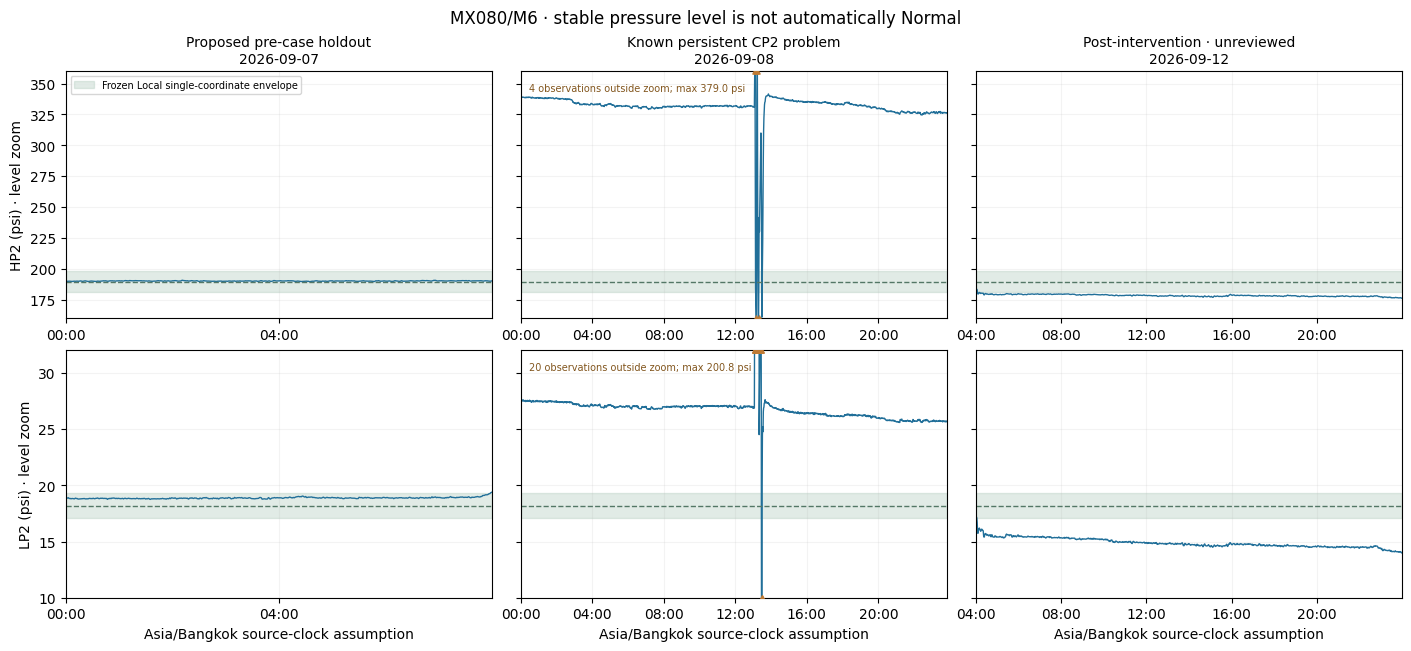

In [3]:
cases=pd.DataFrame({k:qa[k] for k in ['proposed_normal_holdout','known_case','suspected_acquisition','post_intervention_unreviewed']}).T
display(cases)
model=next(m for m in fleet.models() if m['machine']=='080' and m['module']==6 and m['context']=='SV_OFF')
views=[('2026-09-07','00:00','08:00','Proposed pre-case holdout'),('2026-09-08','00:00','23:50','Known persistent CP2 problem'),('2026-09-12','04:00','23:59','Post-intervention · unreviewed')]
fig,axes=plt.subplots(2,3,figsize=(14,6.4),sharey='row',layout='constrained')
for col,(day,start,end,label) in enumerate(views):
    rows=day_rows('080',day,6);points=fleet.evaluate('080',6,rows)['points']
    data=pd.DataFrame(rows);data['assessment']=[p['assessment'] for p in points]
    data=data[data.time.ge(day+'T'+start)&data.time.lt(day+'T'+end)]
    stamp=pd.to_datetime(data.time)
    for ax,feature,index in [(axes[0,col],'hp2',2),(axes[1,col],'lp2',3)]:
        values=pd.Series(data[feature].where(data.assessment.ne('DATA_QUALITY')).to_numpy(),index=stamp)
        values=values.reindex(pd.date_range(stamp.min(),stamp.max(),freq='min'))
        ax.plot(values.index,values.values,color='#216f99',lw=1)
        limits=(160,360) if index==2 else (10,32)
        outside=values[(values<limits[0])|(values>limits[1])].dropna()
        if len(outside):
            ax.scatter(outside.index,outside.clip(*limits),marker='^',s=14,color='#be7a34',zorder=4)
            ax.text(.02,.92,f'{len(outside)} observations outside zoom; max {outside.max():.1f} psi',transform=ax.transAxes,fontsize=7,color='#82561e')
        ax.set_xlim(stamp.min(),stamp.max())
        center=model['center'][index];radius=model['absolute_threshold']*model['scale'][index]
        ax.axhspan(center-radius,center+radius,color='#9ebfaf',alpha=.3,label='Frozen Local single-coordinate envelope')
        ax.axhline(center,color='#537766',ls='--',lw=1)
        ax.grid(alpha=.15)
        import matplotlib.dates as mdates
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'));ax.xaxis.set_major_locator(mdates.HourLocator(interval=4))
    axes[0,col].set_title(label+'\n'+day,fontsize=10)
    axes[1,col].set_xlabel('Asia/Bangkok source-clock assumption')
axes[0,0].set_ylabel('HP2 (psi) · level zoom');axes[1,0].set_ylabel('LP2 (psi) · level zoom')
axes[0,0].set_ylim(160,360);axes[1,0].set_ylim(10,32)
axes[0,0].legend(fontsize=7,loc='upper left')
fig.suptitle('MX080/M6 · stable pressure level is not automatically Normal')
fig.savefig(out/'cp2-shadow-regression.png',dpi=150);plt.show()

In [4]:
display(pd.DataFrame([qa['inference'],qa.get('http',{})]))
display(pd.DataFrame(qa['local_shadow_switch']['switches']))
assert qa['local_shadow_switch']['stale_revision_rejected']
assert all(qa['registry'][t]['unchanged'] for t in ['ht9046mx_calibration_profile','ht9046mx_active_calibration_profile'])
print('Healthy FPR verified:',qa['healthy_fpr_verified'],'Prospective verified:',qa['prospective_verified'])

,points,repeats,p50_ms,p95_ms,scope,distinct_views,clients,requests,successes,prepared_first_read_p95_ms,warm_p50_ms,warm_p95_ms,warm_max_ms
0,1430.0,20.0,34.39555,50.827455,Full one-module-day numerical/control/quality/...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,"Bounded prepared HTTP evidence, not cold SQL i...",96.0,10.0,120.0,120.0,139.759875,108.33085,201.464505,223.3704


,revision,bundle_id,previous_bundle_id
0,13,fleet-stable-v1-e54191096d8ffe99bdc13bbe,fleet-stable-v1-7bddf4bc048624cb2482b135
1,14,fleet-stable-v1-2f656893533033ab994e3713,fleet-stable-v1-e54191096d8ffe99bdc13bbe
2,15,fleet-stable-v1-e54191096d8ffe99bdc13bbe,fleet-stable-v1-2f656893533033ab994e3713
3,16,fleet-stable-v1-2f656893533033ab994e3713,fleet-stable-v1-e54191096d8ffe99bdc13bbe


Healthy FPR verified: False Prospective verified: False


## Takeaways
This handoff establishes portable frozen inference, checksum validation, local Shadow selection/rollback, stale-revision rejection and prepared graph reads. It does not establish independent healthy false-alert rates, production hardware/regime eligibility or target-Server/live worker acceptance. ARX is not needed in this runtime; offline challengers remain available.
### Reproduce and retrain
Run `python -m notebooks.support.fleet_stable_build`, then `python -m notebooks.support.fleet_stable_qa --http` with the local API running. Retraining accepts `--source-root`, `--plan` and `--output-root`; every build produces a new immutable package and does not change the Shadow pointer.
The Server runbook is deployment/FLEET_STABLE_V1_RUNBOOK_20261006.md. Common ledger adapters are in fleet_stable_events.py; the producer must append them atomically with its checkpoint. Existing source-second transitions stay in their original common-event capture. There is no GET-triggered event write or new source/backfill import in this task.